<a href="https://colab.research.google.com/github/Gizeh-Gutierrez/Maestria_programacion/blob/main/PracticaRegresionLinealMultiple_271752.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: Gizeh Gutierrez
*   Matrícula: 271752

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


# Cargar datos
df = pd.read_csv('/content/drive/MyDrive/ClassFiles/advertising.csv')

# Primeras filas
print("Primeras filas del dataset:")
display(df.head())

# Descripción est.
print("\nDescripción estadística:")
display(df.describe())


Mounted at /content/drive
Primeras filas del dataset:


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9



Descripción estadística:


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

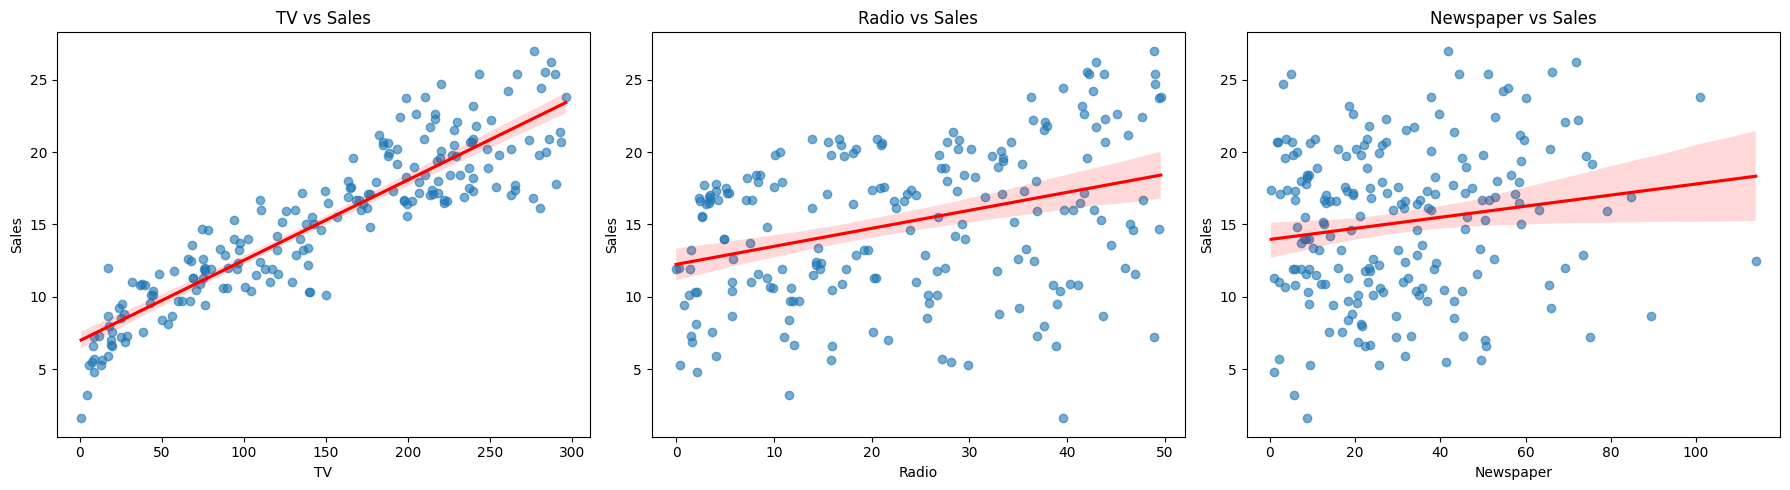

In [2]:


# Variables
variables = ["TV", "Radio", "Newspaper"]

# gráficos
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, var in enumerate(variables):
    sns.regplot(x=var, y="Sales", data=df, ax=axes[i],
                scatter_kws={"alpha": 0.6}, line_kws={"color": "red"})
    axes[i].set_title(f"{var} vs Sales")

plt.tight_layout()
plt.show()



### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

Las variables más correlacionadas con Sales son TV y Radio, ya que presentan las correlaciones positivas más altas. Newspaper tiene una correlación mucho menor con Sales, por lo que su relación con las ventas es más débil.

Entre los predictores no existe una correlación alta. Las correlaciones entre TV, Radio y Newspaper son bajas, por lo que no parece haber un problema importante de multicolinealidad.Por lo que las variables pueden utilizarse conjuntamente en el modelo de regresión sin generar una redundancia de información.

                 TV     Radio  Newspaper     Sales
TV         1.000000  0.054809   0.056648  0.901208
Radio      0.054809  1.000000   0.354104  0.349631
Newspaper  0.056648  0.354104   1.000000  0.157960
Sales      0.901208  0.349631   0.157960  1.000000


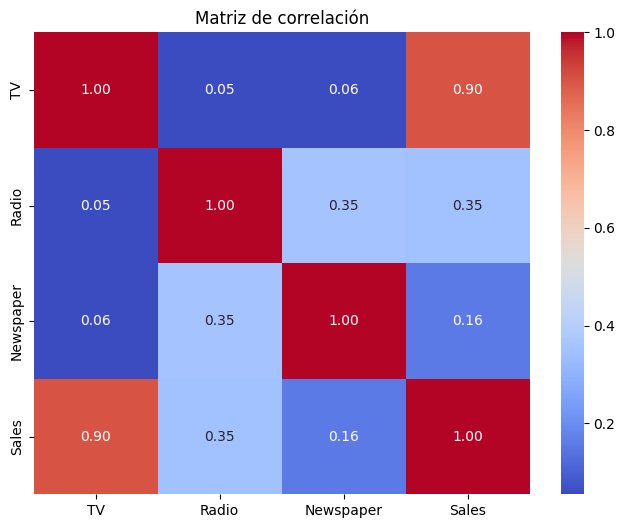

In [3]:


# Matriz de correlación
corr_matrix = df.corr(numeric_only=True)

print(corr_matrix)

# Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de correlación")
plt.show()


## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?

Los valores de VIF obtenidos son TV = 1.00, Radio = 1.14 y Newspaper = 1.15. Ninguna variable tiene un VIF mayor a 5 ni mayor a 10. Esto indica que no existe un problema de multicolinealidad entre los predictores.

Como los valores están muy cercanos a 1, las variables aportan información prácticamente independiente al modelo. Por lo tanto, los coeficientes de la regresión serán estables y su interpretación será confiable. En este caso, no es necesario eliminar ninguna variable.

    Variable       VIF
0         TV  1.004611
1      Radio  1.144952
2  Newspaper  1.145187


/tmp/ipykernel_2916/2929999665.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=vif, x="Variable", y="VIF", palette="Blues_d")


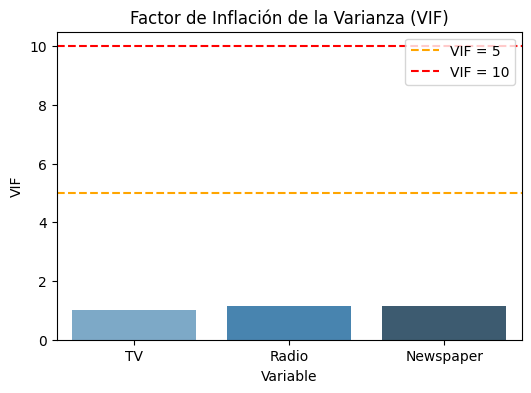

In [4]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Variables predictoras
X = df[["TV", "Radio", "Newspaper"]]

# Calcular VIF
vif = pd.DataFrame()
vif["Variable"] = X.columns
vif["VIF"] = [variance_inflation_factor(X.values, i)
              for i in range(X.shape[1])]

print(vif)

# Gráfico de barras
plt.figure(figsize=(6,4))
sns.barplot(data=vif, x="Variable", y="VIF", palette="Blues_d")
plt.axhline(5, color="orange", linestyle="--", label="VIF = 5")
plt.axhline(10, color="red", linestyle="--", label="VIF = 10")
plt.title("Factor de Inflación de la Varianza (VIF)")
plt.legend()
plt.show()

## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

Intercepto (4.625): si no se invierte en publicidad, las ventas esperadas son 4.63.
TV (0.054): por cada unidad adicional invertida en TV, las ventas aumentan 0.054 unidades.
Radio (0.107): por cada unidad adicional invertida en Radio, las ventas aumentan 0.107 unidades.
Newspaper (0.0003): por cada unidad adicional invertida en Newspaper, las ventas aumentan solo 0.0003 unidades.

Es decir  el radio tiene el mayor impacto en las ventas, seguida de TV. Newspaper tiene un efecto casi nulo.

In [5]:
from sklearn.linear_model import LinearRegression

# Variables predictoras y variable objetivo
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

# Entrenar modelo
modelo = LinearRegression()
modelo.fit(X, y)

# Intercepto
print("Intercepto:", modelo.intercept_)

# Coeficientes
coeficientes = pd.DataFrame({
    "Variable": X.columns,
    "Coeficiente": modelo.coef_
})

print(coeficientes)

Intercepto: 4.625124078808653
    Variable  Coeficiente
0         TV     0.054446
1      Radio     0.107001
2  Newspaper     0.000336


### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

Sí, los residuos parecen distribuirse de forma normal. El histograma tiene una forma de campana y está centrado, lo que indica que los errores se distribuyen de manera equilibrada entre sobreestimaciones y subestimaciones.

Se observan algunos valores extremos en la cola izquierda, pero no son suficientes para romper  la normalidad.



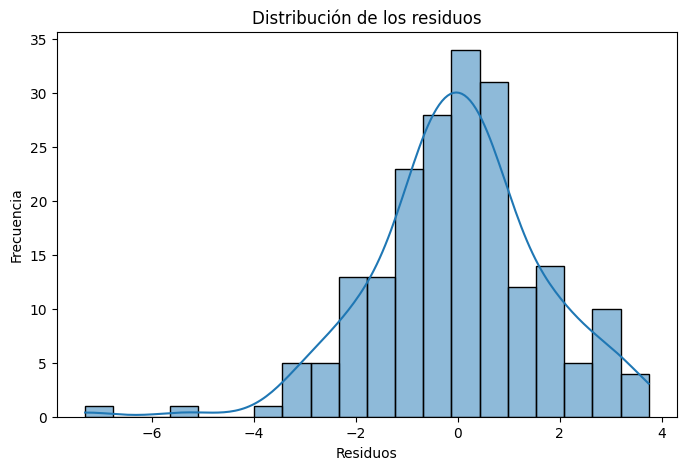

In [6]:

# Predicciones
y_pred = modelo.predict(X)

# Residuos
residuos = y - y_pred

# Histograma con KDE
plt.figure(figsize=(8,5))
sns.histplot(residuos, kde=True, bins=20)
plt.title("Distribución de los residuos")
plt.xlabel("Residuos")
plt.ylabel("Frecuencia")
plt.show()

### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

No se observan patrones. Los puntos están distribuidos alrededor de la línea horizontal en 0 y se dispersan de manera  aleatoria.



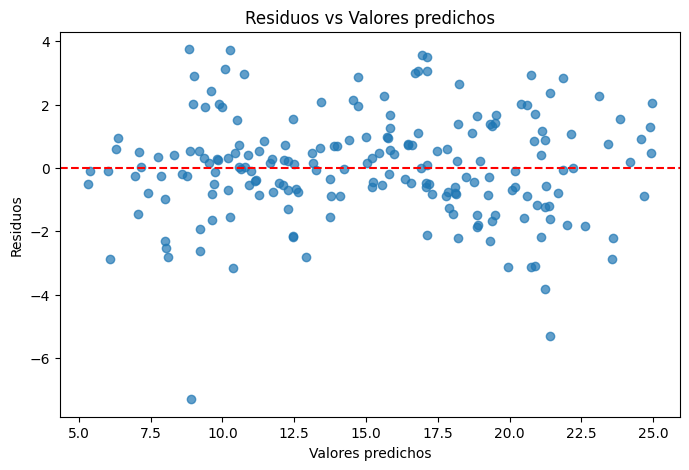

In [7]:
# Gráfico de residuos vs valores predichos
plt.figure(figsize=(8,5))
plt.scatter(y_pred, residuos, alpha=0.7)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.title("Residuos vs Valores predichos")
plt.show()

### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

La mayoría de los puntos del Q-Q Plot se alinean cerca de la línea diagonal, lo que nos dice que los residuos tienen una distribución normal. Solo se observan pequeñas desviaciones en los extremos, especialmente en la cola izquierda, donde aparecen algunos valores atípicos.

En general, no hay desviaciones sistemáticas de la línea, por lo que el supuesto de normalidad de los residuos se cumple.

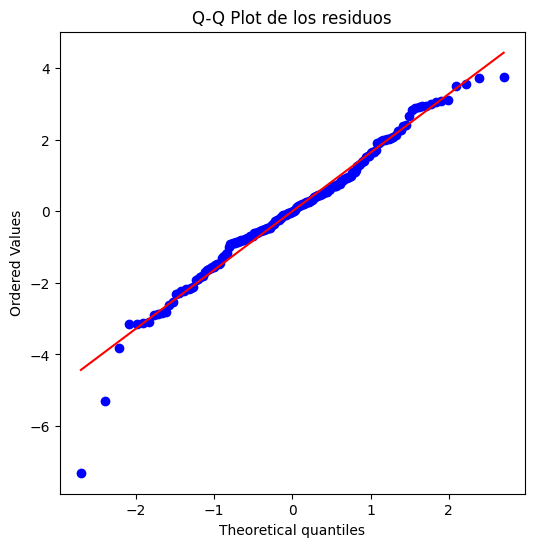

In [8]:
import scipy.stats as stats

# Q-Q Plot
plt.figure(figsize=(6,6))
stats.probplot(residuos, dist="norm", plot=plt)
plt.title("Q-Q Plot de los residuos")
plt.show()


### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


Las métricas indican que el modelo tiene un buen ajuste. El MSE = 2.706 y el RMSE = 1.645 nos dicen que el error de predicción esbajo. El R² = 0.903 indica que el modelo explica aproximadamente el 90.3% de la variabilidad de las ventas.En resumen las variables TV, Radio y Newspaper permiten predecir las ventas con buena precisión.

In [9]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Predicciones
y_pred = modelo.predict(X)

# Métricas
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)

print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MSE: 2.706006147627315
RMSE: 1.6449942697855562
R²: 0.9025912899684558


### 4.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3.¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

Los puntos se encuentran muy cerca de la línea diagonal, lo que indica que las ventas predichas son muy similares a las ventas reales. Esto muestra que el modelo buen desempeño realizando predicciones.

En la gráfica  podemos ver que cuanto más cerca estén los puntos de la línea, menor es el error. También permite identificarvalores atípicos o predicciones con mayor error. En general, se observa un buen ajuste del modelo, consistente con el R² = 0.903 obtenido anteriormente.

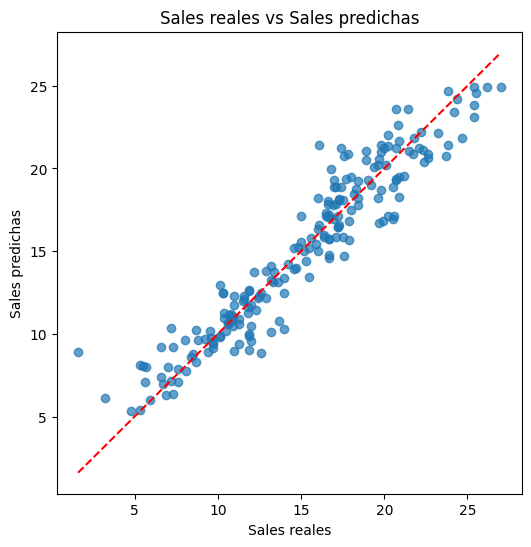

In [10]:
plt.figure(figsize=(6,6))
plt.scatter(y, y_pred, alpha=0.7)

# Línea ideal
plt.plot([y.min(), y.max()],
         [y.min(), y.max()],
         color='red', linestyle='--')

plt.xlabel("Sales reales")
plt.ylabel("Sales predichas")
plt.title("Sales reales vs Sales predichas")
plt.show()

### 4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


Las variables con p-value menor a 0.05 son TV (0.000) y Radio (0.000).

Esto significa que TV y Radio son variables estadísticamente significativas para explicar las ventas, ya que existe evidencia suficiente de que influyen en la variable Sales.

Por otro lado, Newspaper tiene un p-value de 0.954, que es mucho mayor que 0.05, por lo que no es estadísticamente significativa. Esto indica que su efecto sobre las ventas no es relevante cuando se consideran conjuntamente TV y Radio en el modelo.


In [11]:
import statsmodels.api as sm

# Variables predictoras
X = df[["TV", "Radio", "Newspaper"]]

# Agregar constante
X_sm = sm.add_constant(X)

# Ajustar modelo
modelo_sm = sm.OLS(y, X_sm).fit()

# Resumen
print(modelo_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        23:52:32   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.0

##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

No se detectó multicolinealidad entre las variables predictoras, ya que todos los valores de VIF fueron cercanos a 1 (TV = 1.00, Radio = 1.14 y Newspaper = 1.15). asi que no fue necesario eliminar ninguna variable y los resultados de la Parte 4 se mantienen iguales.

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal con la variable dependiente. Elimina aquellas que presenten esta característica y realiza lo siguiente.

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

Se eliminó Newspaper ya que no muestra una relación significativa con las ventas. Con TV y Radio se conserva la capacidad de explicar las ventas de forma correcta y resulta  más simple, utilizando únicamente las variables que aportan información relevante

In [12]:
from sklearn.linear_model import LinearRegression

X_red = df[["TV", "Radio"]]
y = df["Sales"]

modelo_red = LinearRegression()
modelo_red.fit(X_red, y)

print("Intercepto:", modelo_red.intercept_)

coeficientes = pd.DataFrame({
    "Variable": X_red.columns,
    "Coeficiente": modelo_red.coef_
})

print(coeficientes)

y_pred_red = modelo_red.predict(X_red)
residuos_red = y - y_pred_red


mse = mean_squared_error(y, y_pred_red)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred_red)

print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

Intercepto: 4.630879464097768
  Variable  Coeficiente
0       TV     0.054449
1    Radio     0.107175
MSE: 2.7060525778834883
RMSE: 1.6450083823140502
R²: 0.9025896186081139


##7. Conclusiones.

¿Cuál de los tres modelos construidos fue el mejor?
¿Cuál fue el atributo que mas influencia tiene en las ventas?

El mejor modelo fue el que utiliza TV y Radio, eliminando Newspaper. Esto ya que Newspaper no es una variable significativa, por lo que no aporta información relevante para predecir las ventas.

El atributo con mayor influencia en las ventas fue Radio, ya que presentó el coeficiente más alto lo que significa que, por cada unidad adicional invertida, Radio genera el mayor incremento en ventas.
